## 1. Load the dataset into tables

**What this code does:** it goes through all three splits (train, val, test-dev) and loads the dataset into two pandas tables. It does not change any files and does not look at the picture content.

- For every image it reads only the file header, to get the real width and height.
- For every annotation `.txt` file it reads each line (one line = one annotated box) and splits it into the 8 VisDrone fields: `x, y, w, h, score, category, truncation, occlusion`.
- Lines that cannot be parsed (wrong number of fields or non-numeric values) are not dropped silently. They are saved in `bad_lines` as evidence.

**Result:**
- `boxes_df`: one row per box, with a `split` column.
- `images_df`: one row per image, with size, number of annotation lines and number of targets.
- `is_target = (score == 1) and (category != 0)`. Ignored regions and score=0 boxes stay in the table, but they are not counted as objects.

In [4]:
from pathlib import Path
import pandas as pd
from PIL import Image
from tqdm import tqdm

ROOT = Path.home() / "Documents" / "Machine Vision Course"
SPLITS = {"train": "VisDrone2019-DET-train",
          "val": "VisDrone2019-DET-val",
          "test": "VisDrone2019-DET-test-dev"}
CLASSES = {0: "ignored", 1: "pedestrian", 2: "people", 3: "bicycle", 4: "car",
           5: "van", 6: "truck", 7: "tricycle", 8: "awning-tricycle",
           9: "bus", 10: "motor", 11: "others"}
COLS = ["x", "y", "w", "h", "score", "category", "truncation", "occlusion"]

box_rows, img_rows, bad_lines = [], [], []

for split, folder in SPLITS.items():
    img_dir = ROOT / folder / "images"
    ann_dir = ROOT / folder / "annotations"
    for img_path in tqdm(sorted(img_dir.glob("*.jpg")), desc=split):
        image_id = img_path.stem
        with Image.open(img_path) as im:
            W, H = im.size
        ann_path = ann_dir / f"{image_id}.txt"
        has_ann = ann_path.exists()
        n_lines = 0
        if has_ann:
            for i, line in enumerate(ann_path.read_text().splitlines()):
                line = line.strip()
                if not line:
                    continue
                parts = line.split(",")
                try:
                    if len(parts) != 8:
                        raise ValueError(f"{len(parts)} fields")
                    vals = [int(p) for p in parts]
                except ValueError as e:
                    bad_lines.append((split, image_id, i + 1, str(e), line))
                    continue
                box_rows.append([split, image_id, *vals])
                n_lines += 1
        img_rows.append([split, image_id, str(img_path), W, H, has_ann, n_lines])

boxes_df = pd.DataFrame(box_rows, columns=["split", "image_id", *COLS])
boxes_df["is_target"] = (boxes_df["score"] == 1) & (boxes_df["category"] != 0)

images_df = pd.DataFrame(img_rows, columns=["split", "image_id", "path", "W", "H", "has_ann", "n_lines"])
images_df["n_objects"] = (boxes_df[boxes_df.is_target]
                          .groupby(["split", "image_id"]).size()
                          .reindex(pd.MultiIndex.from_frame(images_df[["split", "image_id"]]))
                          .fillna(0).astype(int).values)

print(images_df.groupby("split").size())
print(boxes_df.groupby("split").agg(rows=("image_id", "size"), targets=("is_target", "sum")))
print("bad lines:", len(bad_lines))
print(images_df[["W", "H"]].value_counts().head(10))

test: 100%|██████████████████████████████| 1610/1610 [00:00<00:00, 2282.37it/s]


split
test     1610
train    6471
val       548
dtype: int64
         rows  targets
split                 
test    77547    75102
train  353516   343171
val     40169    38759
bad lines: 34
W     H   
1400  1050    2772
      788     2232
1360  765     1318
2000  1500     772
1916  1078     688
960   540      420
1920  1080     394
1398  1048      30
1344  756        1
1389  1042       1
Name: count, dtype: int64


## 2. Structural audit

**What this code does:** automatic checks on all three splits, reported separately for train, val and test.

- **Bad lines:** annotation lines that could not be parsed (wrong number of fields or non-numeric values).
- **Image ↔ annotation matching:** every image must have an annotation file with the same ID, and the other way round. Finds lost or extra files.
- **Image decoding:** OpenCV tries to open every image. Finds corrupt files.
- **Box checks:** category outside 0..11, width or height <= 0, box outside the image, score not 0 or 1. Finds broken annotations.
- **Empty annotation files:** images with no lines at all, and images with lines but no targets.

**Why:** these are cheap automatic checks that catch formal defects before we spend time on visual review. The per-split table is the evidence for the report.

In [5]:
import cv2

# ---------- 1. bad lines (collected during loading) ----------
bad_df = pd.DataFrame(bad_lines, columns=["split", "image_id", "line_no", "error", "line"])
print("BAD LINES per split:")
print(bad_df["split"].value_counts().reindex(SPLITS.keys(), fill_value=0), "\n")
print("Error types:\n", bad_df["error"].value_counts(), "\n")
print("First 10 bad lines:\n", bad_df.head(10).to_string(), "\n")

# ---------- 2. image <-> annotation matching, per split ----------
match_rows = []
for split, folder in SPLITS.items():
    imgs = {p.stem for p in (ROOT / folder / "images").glob("*.jpg")}   # set of image IDs
    anns = {p.stem for p in (ROOT / folder / "annotations").glob("*.txt")}  # set of annotation IDs
    match_rows.append({"split": split,
                       "images": len(imgs),
                       "annotations": len(anns),
                       "img_without_ann": len(imgs - anns),   # set difference = lost files
                       "ann_without_img": len(anns - imgs)})
match_df = pd.DataFrame(match_rows).set_index("split")

# ---------- 3. image decoding with OpenCV (reads every pixel, takes ~1-2 min) ----------
corrupt = []
for r in tqdm(images_df.itertuples(), total=len(images_df), desc="decode"):
    if cv2.imread(r.path) is None:          # returns None if the file cannot be decoded
        corrupt.append((r.split, r.image_id))
corrupt_per_split = pd.Series([s for s, _ in corrupt], dtype=str).value_counts() \
                      .reindex(SPLITS.keys(), fill_value=0)

# ---------- 4. box checks, per split ----------
# attach each image's real size to its boxes, so we can test "outside the image"
b = boxes_df.merge(images_df[["split", "image_id", "W", "H"]], on=["split", "image_id"])
b["bad_category"] = ~b.category.between(0, 11)
b["non_positive_wh"] = (b.w <= 0) | (b.h <= 0)
b["outside_image"] = (b.x < 0) | (b.y < 0) | (b.x + b.w > b.W) | (b.y + b.h > b.H)
b["bad_score"] = ~b.score.isin([0, 1])
box_checks = b.groupby("split")[["bad_category", "non_positive_wh",
                                 "outside_image", "bad_score"]].sum()

# ---------- 5. empty annotations, per split ----------
empty_files = images_df[images_df.n_lines == 0].groupby("split").size() \
                .reindex(SPLITS.keys(), fill_value=0)
no_targets = images_df[images_df.n_objects == 0].groupby("split").size() \
                .reindex(SPLITS.keys(), fill_value=0)

# ---------- summary table (this goes into the report) ----------
summary = match_df.copy()
summary["bad_lines"] = bad_df["split"].value_counts().reindex(SPLITS.keys(), fill_value=0)
summary["corrupt_images"] = corrupt_per_split
summary = summary.join(box_checks)
summary["empty_ann_files"] = empty_files
summary["images_0_targets"] = no_targets
summary["targets"] = boxes_df[boxes_df.is_target].groupby("split").size()
print(summary.T)

BAD LINES per split:
split
train    34
val       0
test      0
Name: count, dtype: int64 

Error types:
 error
9 fields    34
Name: count, dtype: int64 

First 10 bad lines:
    split                 image_id  line_no     error                      line
0  train  9999974_00000_d_0000053        1  9 fields  440,541,271,152,1,6,0,0,
1  train  9999974_00000_d_0000053        2  9 fields   436,772,134,72,1,5,0,0,
2  train  9999974_00000_d_0000053        3  9 fields   601,713,60,39,1,10,0,0,
3  train  9999974_00000_d_0000053        4  9 fields   486,706,102,59,1,8,0,0,
4  train  9999974_00000_d_0000053        5  9 fields   397,978,167,90,1,4,0,0,
5  train  9999974_00000_d_0000053        6  9 fields   718,1063,23,14,1,1,1,0,
6  train  9999974_00000_d_0000053        7  9 fields     696,13,21,33,1,3,0,0,
7  train  9999974_00000_d_0000053        8  9 fields    1124,73,98,62,1,5,0,1,
8  train  9999974_00000_d_0000053        9  9 fields    1089,35,84,46,1,7,0,1,
9  train  9999974_00000_d_0000053  

decode: 100%|██████████████████████████████| 8629/8629 [02:46<00:00, 51.98it/s]


split              train    val   test
images              6471    548   1610
annotations         6471    548   1610
img_without_ann        0      0      0
ann_without_img        0      0      0
bad_lines             34      0      0
corrupt_images         0      0      0
bad_category           0      0      0
non_positive_wh        3      0      0
outside_image          0      0      0
bad_score              0      0      0
empty_ann_files        1      0      0
images_0_targets       1      0      0
targets           343171  38759  75102


In [6]:
# 1. the trailing-comma file: raw text from disk
p = ROOT / SPLITS["train"] / "annotations" / "9999974_00000_d_0000053.txt"
lines = p.read_text().splitlines()
print("lines in file:", len(lines))
print("first 3 lines:", lines[:3])

# 2. is it the "empty" file?
print(images_df[images_df.image_id == "9999974_00000_d_0000053"]
      [["split", "image_id", "W", "H", "n_lines", "n_objects"]])

# 3. the boxes with width or height <= 0
bad_boxes = boxes_df[(boxes_df.w <= 0) | (boxes_df.h <= 0)]
print(bad_boxes.to_string())

lines in file: 34
first 3 lines: ['440,541,271,152,1,6,0,0,', '436,772,134,72,1,5,0,0,', '601,713,60,39,1,10,0,0,']
      split                 image_id     W     H  n_lines  n_objects
4504  train  9999974_00000_d_0000053  1916  1078        0          0
        split                 image_id     x    y   w  h  score  category  truncation  occlusion  is_target
66237   train  0000293_03401_d_0000939  1008  374   3  0      0         0           0          0      False
277382  train  9999985_00000_d_0000020   611  158   4  0      1         4           0          0       True
342661  train  9999999_00590_d_0000267   545  414  10  0      0         0           0          0      False


Matplotlib is building the font cache; this may take a moment.


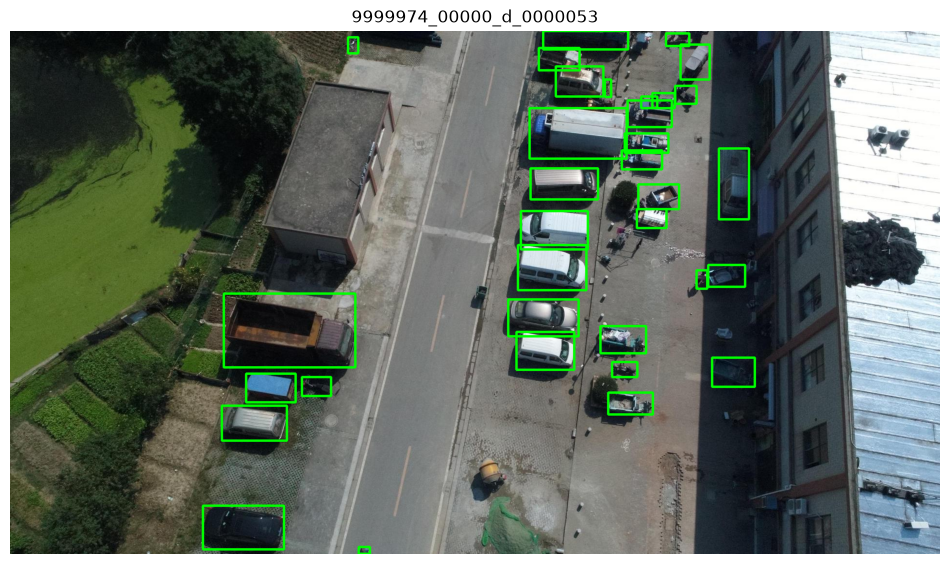

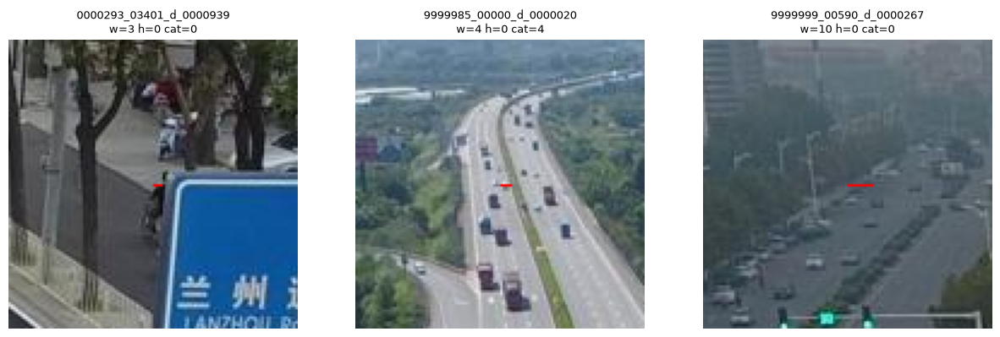

In [7]:
import cv2
import matplotlib.pyplot as plt

FIG = Path.home() / "Documents" / "visdrone-audit" / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def img_path(split, image_id):
    return ROOT / SPLITS[split] / "images" / f"{image_id}.jpg"

# --- Evidence 1: draw the 34 boxes of the trailing-comma file ---
iid = "9999974_00000_d_0000053"
img = cv2.imread(str(img_path("train", iid)))
for line in lines:                                    # `lines` comes from the previous cell
    x, y, w, h, score, cat, tr, oc = [int(v) for v in line.rstrip(",").split(",")]
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 3)
cv2.imwrite(str(FIG / "finding1_trailing_comma.jpg"), img)
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))      # OpenCV is BGR, matplotlib wants RGB
plt.axis("off"); plt.title(iid); plt.show()

# --- Evidence 2: zoomed crops around the 3 zero-height boxes ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, r in zip(axes, bad_boxes.itertuples()):
    im = cv2.imread(str(img_path(r.split, r.image_id)))
    cv2.rectangle(im, (r.x, r.y), (r.x + r.w, r.y + r.h), (0, 0, 255), 1)
    x0, y0 = max(0, r.x - 60), max(0, r.y - 60)
    crop = im[y0:r.y + 60, x0:r.x + 60]
    ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{r.image_id}\nw={r.w} h={r.h} cat={r.category}", fontsize=9)
    ax.axis("off")
plt.savefig(FIG / "finding2_zero_size_boxes.png", bbox_inches="tight")
plt.show()


## 3. Distributions per split

**What this does:** measures what the dataset contains, separately for train, val and test. Only targets are counted (`score == 1` and `category != 0`); ignored regions are excluded.

- **Class distribution:** objects per class, images per class, share of each class, and R = N_max / N_min. Shows imbalance, and whether val/test have the same class mix as train.
- **Box size:** share of small (< 32²), medium (32²–96²) and large (>= 96²) boxes by area, on the original image and after resizing to a 640 and a 1408 model input. Each image uses its own width and height.
- **Scene density:** objects per image (median, P90, P95, P99, max).

**Why:** a detector learns from what the data contains. Rare classes, a high share of tiny boxes, or a split with a different distribution than train can limit or distort the results.

Cell 1: classes (code cell, run with Shift+Enter):

                  objects               images            share_%         \
split               train    val   test  train  val  test   train    val   
1 pedestrian        79335   8844  21006   5365  520  1197   23.12  22.82   
2 people            27059   5125   6376   3947  482   797    7.88  13.22   
3 bicycle           10477   1287   1302   2754  364   377    3.05   3.32   
4 car              144865  14064  28074   6132  515  1530   42.21  36.29   
5 van               24950   1975   5771   4947  421  1168    7.27   5.10   
6 truck             12871    750   2659   3550  266   750    3.75   1.94   
7 tricycle           4803   1045    530   1687  337   245    1.40   2.70   
8 awning-tricycle    3243    532    599   1150  220   233    0.95   1.37   
9 bus                5926    251   2940   2023  131   838    1.73   0.65   
10 motor            29642   4886   5845   4236  485   794    8.64  12.61   

                          
split               test  
1 pedestrian       27.97  
2 peop

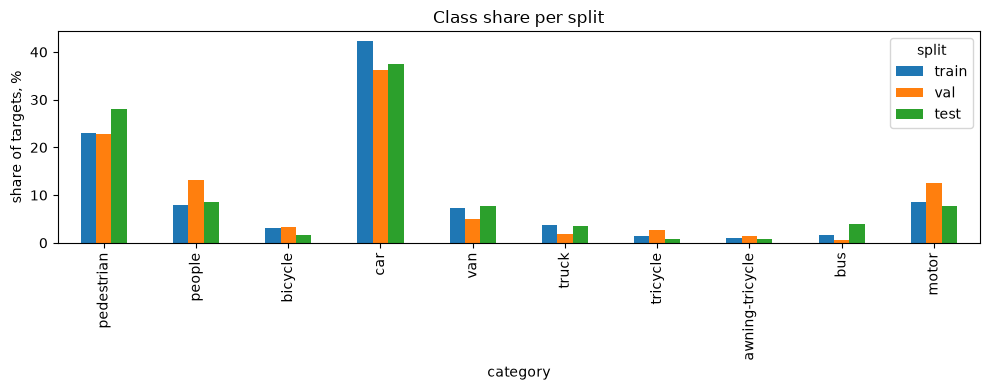

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# targets only: real objects that count in evaluation
t = boxes_df[boxes_df.is_target].copy()

# number of objects per class and split (rows = class id, columns = split)
objects = t.groupby(["category", "split"]).size().unstack("split")[list(SPLITS)]

# number of DIFFERENT images that contain each class (nunique, not size)
images = t.groupby(["category", "split"])["image_id"].nunique().unstack("split")[list(SPLITS)]

# share of each class inside its own split, in % (each column sums to 100)
share = objects / objects.sum() * 100

class_table = pd.concat({"objects": objects, "images": images, "share_%": share.round(2)}, axis=1)
class_table.index = [f"{c} {CLASSES[c]}" for c in class_table.index]
print(class_table)

# imbalance ratio R = most frequent class / least frequent class, per split
print("\nR = N_max / N_min per split:")
print((objects.max() / objects.min()).round(1))

# bar chart: class share per split (saved for the report)
FIG = Path.home() / "Documents" / "visdrone-audit" / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
share.rename(index=CLASSES).plot(kind="bar", figsize=(10, 4))
plt.ylabel("share of targets, %")
plt.title("Class share per split")
plt.tight_layout()
plt.savefig(FIG / "class_share_per_split.png")
plt.show()

Cell 2: box sizes:

In [9]:
# attach each image's real size to its boxes
t = t.merge(images_df[["split", "image_id", "W", "H"]], on=["split", "image_id"])
t["area"] = t.w * t.h                                   # box area in original pixels

bins = [0, 32**2, 96**2, np.inf]                        # COCO-style thresholds
labels = ["small", "medium", "large"]

# model input sizes to compare. Scale of a letterboxed image = min(S/W, S/H).
# Area changes with scale squared, because both sides shrink.
settings = {"original": t.area}
for S in (640, 1408):
    scale = np.minimum(S / t.W, S / t.H)
    settings[f"resized to {S}"] = t.area * scale**2

for name, area in settings.items():
    cat = pd.cut(area, bins=bins, labels=labels, right=False)
    table = (cat.groupby(t["split"]).value_counts(normalize=True)
                .unstack() * 100).round(1).reindex(list(SPLITS))
    print(f"\n--- {name}: share of boxes, % ---")
    print(table)

# typical box side in original pixels (square root of the area)
print("\nmedian box side, original px:")
print(np.sqrt(t.area).groupby(t["split"]).median().round(1).reindex(list(SPLITS)))


--- original: share of boxes, % ---
area   small  medium  large
split                      
train   60.5    34.0    5.5
val     68.6    28.7    2.8
test    67.7    29.1    3.2

--- resized to 640: share of boxes, % ---
       small  medium  large
split                      
train   90.6     9.2    0.2
val     92.4     7.5    0.1
test    93.2     6.6    0.2

--- resized to 1408: share of boxes, % ---
       small  medium  large
split                      
train   63.9    31.7    4.4
val     64.6    32.2    3.2
test    68.5    28.6    2.9

median box side, original px:
split
train    26.1
val      22.8
test     21.9
Name: area, dtype: float64


Cell 3: density:

In [10]:
# objects per image, per split (includes images with 0 targets)
density = (images_df.groupby("split")["n_objects"]
           .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
           .round(1).reindex(list(SPLITS)))
print(density)

        count  mean   std  min   50%    90%    95%    99%    max
split                                                           
train  6471.0  53.0  43.8  0.0  42.0  104.0  132.0  211.3  902.0
val     548.0  70.7  46.0  1.0  65.0  122.9  157.6  212.0  317.0
test   1610.0  46.6  44.1  1.0  36.0   88.0  123.0  224.7  461.0


## Duplicates and data leakage

**What this does:** checks whether the same or very similar images appear in more than one split, which would make validation/test metrics too optimistic. All 8629 images are checked.

- **SHA-256:** finds byte-identical files, within a split and across splits.
- **Perceptual hash (dHash, `imagehash` library):** finds visually similar images that are not byte-identical. Hamming distance <= 6 is only a heuristic for candidates, not a proof of duplication.
- **Sequence ID:** the first number in the file name. We check whether the same ID appears in different splits.
- **Visual check:** the closest candidate pairs are drawn side by side.

**Limits:** found candidates are not automatically leakage, and finding none does not prove the splits are independent. Nothing is removed from the dataset.

SHA-256 (exact duplicates):

In [11]:
import hashlib

def file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):   # read 1 MB at a time
            h.update(chunk)
    return h.hexdigest()

tqdm.pandas(desc="sha256")
images_df["sha256"] = images_df["path"].progress_apply(file_hash)

# the same file content appearing more than once
dup_groups = images_df.groupby("sha256").filter(lambda g: len(g) > 1)
cross = images_df.groupby("sha256").filter(lambda g: g["split"].nunique() > 1)

print("files that share their content with another file:", len(dup_groups))
print("of those, in groups that span more than one split:", len(cross))
print(dup_groups.sort_values("sha256")[["split", "image_id", "sha256"]].head(20).to_string())

sha256: 100%|█████████████████████████████| 8629/8629 [00:50<00:00, 172.34it/s]


files that share their content with another file: 6
of those, in groups that span more than one split: 0
      split                  image_id                                                            sha256
2321  train   9999950_00000_d_0000079  094db39c7c57e6d9686f823ab72a5ee92d57dc874d08428b3a01e66ad0c91ccc
2328  train  9999950_00000_d_10000080  094db39c7c57e6d9686f823ab72a5ee92d57dc874d08428b3a01e66ad0c91ccc
6483    val   0000022_00000_d_0000004  0bea9d13456e6aa7a92ad1af21a89960eb66916855ed8a2c3d0371b1d7d37bd0
6487    val   0000023_00000_d_0000008  0bea9d13456e6aa7a92ad1af21a89960eb66916855ed8a2c3d0371b1d7d37bd0
625   train   0000239_06450_d_0000017  382de736b27ad4b54466c5c65cec1bbe5d369a8a735605b5ba68fcf285c28067
626   train   0000239_06950_d_0000018  382de736b27ad4b54466c5c65cec1bbe5d369a8a735605b5ba68fcf285c28067


perceptual hash for every image

In [12]:
import imagehash, numpy as np

hashes = []
for path in tqdm(images_df["path"], desc="dhash"):
    with Image.open(path) as im:
        h = imagehash.dhash(im)                        # 8x8 difference hash = 64 bits
    hashes.append(np.packbits(h.hash.flatten()))       # 64 bits -> 8 bytes
H = np.array(hashes)                                    # shape (8629, 8), same row order as images_df
print(H.shape)

dhash: 100%|███████████████████████████████| 8629/8629 [03:28<00:00, 41.32it/s]

(8629, 8)


visually similar images between splits

In [13]:
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)   # bits set in a byte

def close_pairs(idx_a, idx_b, max_d=6, chunk=300):
    A, B = H[idx_a], H[idx_b]
    out = []
    for s in range(0, len(A), chunk):
        x = A[s:s + chunk, None, :] ^ B[None, :, :]        # XOR: differing bits
        d = POP[x].sum(axis=2, dtype=np.uint8)             # Hamming distance for every pair
        ii, jj = np.where(d <= max_d)
        out += [(idx_a[s + i], idx_b[j], int(d[i, j])) for i, j in zip(ii, jj)]
    return out

idx = {s: np.where(images_df["split"].values == s)[0] for s in SPLITS}
rows = []
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    for ia, ib, d in close_pairs(idx[a], idx[b]):
        rows.append((a, images_df.image_id[ia], b, images_df.image_id[ib], d))

cand = pd.DataFrame(rows, columns=["split_a", "id_a", "split_b", "id_b", "distance"])
cand["bucket"] = pd.cut(cand.distance, [-1, 0, 3, 6], labels=["0", "1-3", "4-6"])
print("candidate pairs with distance <= 6:", len(cand))
print(cand.groupby(["split_a", "split_b", "bucket"], observed=False).size().unstack())
print("images involved per split:")
print(pd.concat([cand[["split_a", "id_a"]].set_axis(["split", "id"], axis=1),
                 cand[["split_b", "id_b"]].set_axis(["split", "id"], axis=1)])
        .drop_duplicates().groupby("split").size())

candidate pairs with distance <= 6: 15
bucket           0  1-3  4-6
split_a split_b             
train   test     0    0    2
        val      0    2   10
val     test     0    0    1
images involved per split:
split
test      3
train    10
val       9
dtype: int64


In [14]:
print(cand.sort_values("distance").to_string())

   split_a                     id_a split_b                     id_b  distance bucket
7    train  9999960_00000_d_0000136     val  0000356_01961_d_0000639         2    1-3
10   train  9999960_00000_d_0000136     val  0000356_05097_d_0000655         3    1-3
0    train  0000323_01801_d_0000641     val  0000323_02601_d_0000645         4    4-6
2    train  0000357_00981_d_0000661     val  0000356_02941_d_0000644         5    4-6
13   train  9999956_00000_d_0000009    test  0000299_00000_d_0000088         5    4-6
14     val  0000103_04122_d_0000033    test  0000105_02201_d_0000071         5    4-6
9    train  9999960_00000_d_0000136     val  0000356_04705_d_0000653         5    4-6
1    train  0000323_02401_d_0000644     val  0000323_02601_d_0000645         6    4-6
6    train  9999960_00000_d_0000136     val  0000356_01765_d_0000638         6    4-6
5    train  9999955_00000_d_0000024     val  0000356_01177_d_0000635         6    4-6
4    train  9999945_00000_d_0000102     val  0000356_0

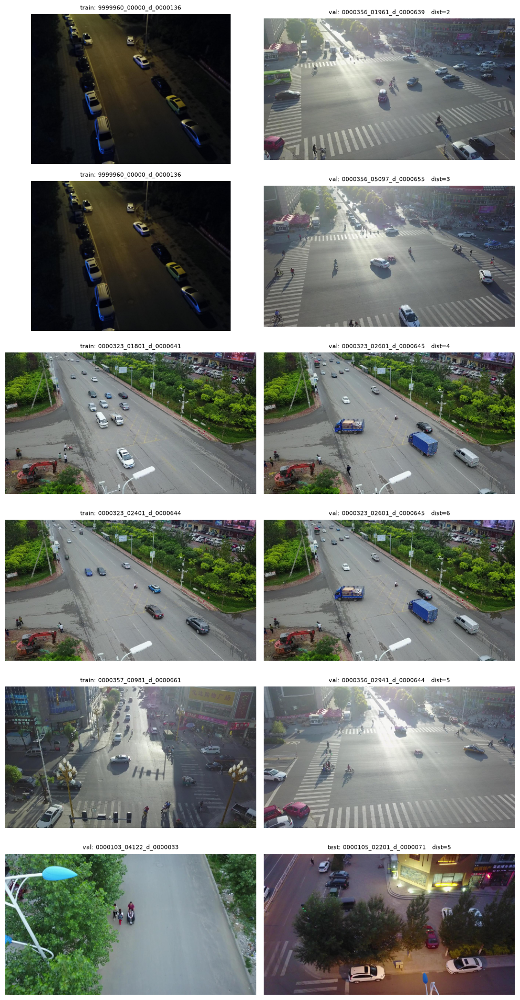

In [15]:
def thumb(split, image_id, w=500):
    im = cv2.imread(str(ROOT / SPLITS[split] / "images" / f"{image_id}.jpg"))
    im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    return cv2.resize(im, (w, int(im.shape[0] * w / im.shape[1])))

sel = cand.loc[[7, 10, 0, 1, 2, 14]]      # rows from the printed table
fig, axes = plt.subplots(len(sel), 2, figsize=(10, 3.2 * len(sel)))
for ax_row, r in zip(axes, sel.itertuples()):
    ax_row[0].imshow(thumb(r.split_a, r.id_a)); ax_row[0].set_title(f"{r.split_a}: {r.id_a}", fontsize=8)
    ax_row[1].imshow(thumb(r.split_b, r.id_b)); ax_row[1].set_title(f"{r.split_b}: {r.id_b}   dist={r.distance}", fontsize=8)
    for ax in ax_row: ax.axis("off")
plt.tight_layout()
plt.savefig(FIG / "leakage_candidates.png", dpi=110)
plt.show()

In [16]:
images_df["seq_id"] = images_df["image_id"].str.split("_").str[0]

print("unique sequence IDs per split:")
print(images_df.groupby("split")["seq_id"].nunique())

seqs = {s: set(images_df.loc[images_df.split == s, "seq_id"]) for s in SPLITS}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    common = seqs[a] & seqs[b]
    n_a = images_df[(images_df.split == a) & images_df.seq_id.isin(common)].shape[0]
    n_b = images_df[(images_df.split == b) & images_df.seq_id.isin(common)].shape[0]
    print(f"\n{a} & {b}: {len(common)} shared sequence IDs, {n_a} images in {a}, {n_b} in {b}")
    print(sorted(common)[:10])

same_name = images_df.groupby("image_id")["split"].nunique()
print("\nfull image IDs present in more than one split:", (same_name > 1).sum())

unique sequence IDs per split:
split
test      61
train    208
val       76
Name: seq_id, dtype: int64

train & val: 24 shared sequence IDs, 297 images in train, 28 in val
['0000072', '0000076', '0000165', '0000166', '0000196', '0000199', '0000220', '0000223', '0000237', '0000256']

train & test: 0 shared sequence IDs, 0 images in train, 0 in test
[]

val & test: 0 shared sequence IDs, 0 images in val, 0 in test
[]

full image IDs present in more than one split: 0


train: 9999950_00000_d_0000079 vs 9999950_00000_d_10000080 | lines 9 / 9 | identical annotations: False
val: 0000022_00000_d_0000004 vs 0000023_00000_d_0000008 | lines 43 / 40 | identical annotations: False
train: 0000239_06450_d_0000017 vs 0000239_06950_d_0000018 | lines 46 / 33 | identical annotations: False


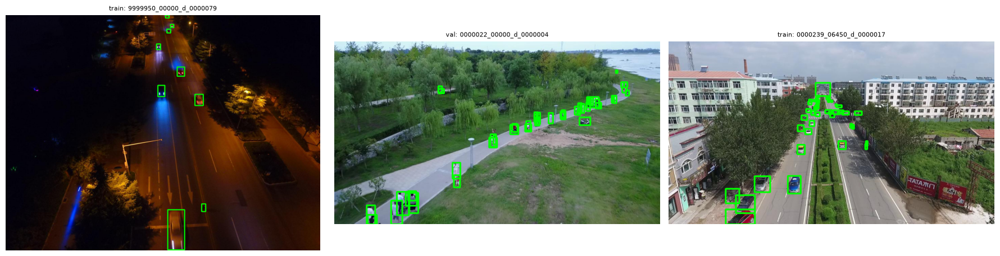

In [17]:
def read_ann(split, image_id):
    p = ROOT / SPLITS[split] / "annotations" / f"{image_id}.txt"
    return [l.strip().rstrip(",") for l in p.read_text().splitlines() if l.strip()]

pairs = [("train", "9999950_00000_d_0000079", "9999950_00000_d_10000080"),
         ("val",   "0000022_00000_d_0000004", "0000023_00000_d_0000008"),
         ("train", "0000239_06450_d_0000017", "0000239_06950_d_0000018")]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (split, a, b) in zip(axes, pairs):
    la, lb = read_ann(split, a), read_ann(split, b)
    print(f"{split}: {a} vs {b} | lines {len(la)} / {len(lb)} | identical annotations: {la == lb}")
    img = cv2.imread(str(ROOT / SPLITS[split] / "images" / f"{a}.jpg"))
    for line in la:
        x, y, w, h = [int(v) for v in line.split(",")[:4]]
        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 3)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{split}: {a}", fontsize=8); ax.axis("off")
plt.tight_layout()
plt.savefig(FIG / "exact_duplicates.png", dpi=110)
plt.show()

In [18]:
EVID = Path.home() / "Documents" / "visdrone-audit" / "reports" / "evidence"
EVID.mkdir(parents=True, exist_ok=True)

common = sorted(seqs["train"] & seqs["val"])
tv = images_df[images_df.seq_id.isin(common) & images_df.split.isin(["train", "val"])]

# one row per shared sequence: how many images it has in train and in val
summary = (tv.groupby(["seq_id", "split"]).size().unstack(fill_value=0)
             .reindex(common)[["train", "val"]])
summary.to_csv(EVID / "shared_sequences_train_val.csv")

# the 28 val images that belong to shared sequences
val_ids = tv[tv.split == "val"][["image_id"]].sort_values("image_id")
val_ids.to_csv(EVID / "val_images_in_shared_sequences.csv", index=False)

print(summary.to_string())
print("\ntotal:", summary.sum().to_dict())
print("\nval images:")
print("\n".join(val_ids.image_id))

split    train  val
seq_id             
0000072     13    1
0000076     18    1
0000165     23    1
0000166      5    1
0000196     10    1
0000199      5    1
0000220     14    1
0000223      6    1
0000237      1    1
0000256     23    2
0000263     11    1
0000273      6    1
0000290     16    1
0000293      9    1
0000300     12    1
0000303     12    1
0000308     11    1
0000313     21    3
0000315      8    1
0000323      7    1
0000342     26    1
0000345     12    1
0000348     22    2
0000358      6    1

total: {'train': 297, 'val': 28}

val images:
0000072_02834_d_0000003
0000076_02142_d_0000009
0000165_04325_d_0000105
0000166_00558_d_0000118
0000196_04512_d_0000144
0000199_01269_d_0000166
0000220_01242_d_0000004
0000223_01802_d_0000005
0000237_00001_d_0000001
0000256_00715_d_0000019
0000256_02173_d_0000030
0000263_02401_d_0000179
0000273_05601_d_0000466
0000290_04001_d_0000867
0000293_03601_d_0000940
0000300_03201_d_0000154
0000303_03401_d_0000200
0000308_04401_d_0000327
0

## 7. Augmentation check

**What this does:** builds a small, constrained augmentation pipeline (horizontal flip, mild brightness/contrast) and checks that the bounding boxes stay correct. It is only a check: no augmented files are saved to the dataset, and in training it would be applied to train only (validation and test must stay unchanged, otherwise changes in the metrics mix model changes with evaluation changes).

- **Box conversion:** VisDrone boxes `(x, y, w, h)` become Pascal VOC `(x_min, y_min, x_max, y_max)`, the format albumentations is configured for. Only target boxes are used. Boxes with width or height 0 (Finding 2) are skipped, because they are geometrically invalid.
- **Numeric check on 200 random train images:** after a flip, every box must match the formula `x_min' = W - x_max`, `x_max' = W - x_min`, y unchanged. Box count and class labels must be preserved. Brightness/contrast must not change any box.
- **Visual check:** original, flipped with transformed boxes (correct), flipped with the old boxes (what happens if the boxes are not transformed), and brightness/contrast.

**Why:** an augmentation that moves the image but not the boxes silently creates wrong training labels, and nothing crashes.

pipelines and helpers:

In [20]:
import random
import albumentations as A
print("albumentations", A.__version__)

# albumentations changed the name of this argument between versions, so try both
try:
    bbox_params = A.BboxParams(coord_format="pascal_voc", label_fields=["class_labels"])
except TypeError:
    bbox_params = A.BboxParams(format="pascal_voc", label_fields=["class_labels"])

# p=1.0 only for the check, so the transform is always applied.
# For real training the lesson uses p=0.5 (flip) and p=0.3 (brightness/contrast).
flip_only  = A.Compose([A.HorizontalFlip(p=1.0)], bbox_params=bbox_params)
color_only = A.Compose([A.RandomBrightnessContrast(brightness_limit=0.1,
                                                   contrast_limit=0.1, p=1.0)],
                       bbox_params=bbox_params)

# valid target boxes only: real objects with positive width and height
t_ok = boxes_df[boxes_df.is_target & (boxes_df.w > 0) & (boxes_df.h > 0)]

def load_sample(split, image_id):
    """Return the RGB image, VOC boxes [x_min, y_min, x_max, y_max] and class labels."""
    img = cv2.imread(str(ROOT / SPLITS[split] / "images" / f"{image_id}.jpg"))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)          # OpenCV is BGR, we want RGB
    rows = t_ok[(t_ok.split == split) & (t_ok.image_id == image_id)]
    bboxes = [[r.x, r.y, r.x + r.w, r.y + r.h] for r in rows.itertuples()]
    return img, bboxes, rows.category.tolist()

albumentations 2.0.8


numeric check (this output goes into the report):

In [21]:
random.seed(42)                                          # same sample every run
train_ids = images_df[images_df.split == "train"].image_id.tolist()
sample_ids = random.sample(train_ids, 200)

n_img = n_before = n_after = 0
max_err = 0.0                 # largest difference to the formula, in pixels
labels_ok = True
color_boxes_same = True
brightness_shift = []

for iid in sample_ids:
    img, bboxes, labels = load_sample("train", iid)
    if not bboxes:
        continue
    H, W = img.shape[:2]
    n_img += 1

    # --- flip: compare albumentations with the formula from the lesson ---
    out = flip_only(image=img, bboxes=bboxes, class_labels=labels)
    expected = [[W - b[2], b[1], W - b[0], b[3]] for b in bboxes]
    n_before += len(bboxes)
    n_after += len(out["bboxes"])
    if len(out["bboxes"]) == len(expected):
        max_err = max(max_err, float(np.abs(np.array(out["bboxes"]) - np.array(expected)).max()))
        labels_ok &= (list(out["class_labels"]) == labels)

    # --- brightness/contrast: the boxes must not change at all ---
    outc = color_only(image=img, bboxes=bboxes, class_labels=labels)
    color_boxes_same &= np.allclose(np.array(outc["bboxes"]), np.array(bboxes), atol=1e-3)
    brightness_shift.append(abs(float(outc["image"].mean()) - float(img.mean())))

print("images tested:", n_img)
print("boxes before / after flip:", n_before, "/", n_after)
print("max difference to the flip formula, px:", round(max_err, 3))
print("class labels preserved:", labels_ok)
print("brightness/contrast leaves boxes unchanged:", color_boxes_same)
print("mean brightness change (0-255 scale): avg", round(np.mean(brightness_shift), 2),
      "max", round(np.max(brightness_shift), 2))

images tested: 200
boxes before / after flip: 11390 / 11390
max difference to the flip formula, px: 0.0
class labels preserved: True
brightness/contrast leaves boxes unchanged: True
mean brightness change (0-255 scale): avg 12.09 max 34.38


visual check (saves a figure for the report):


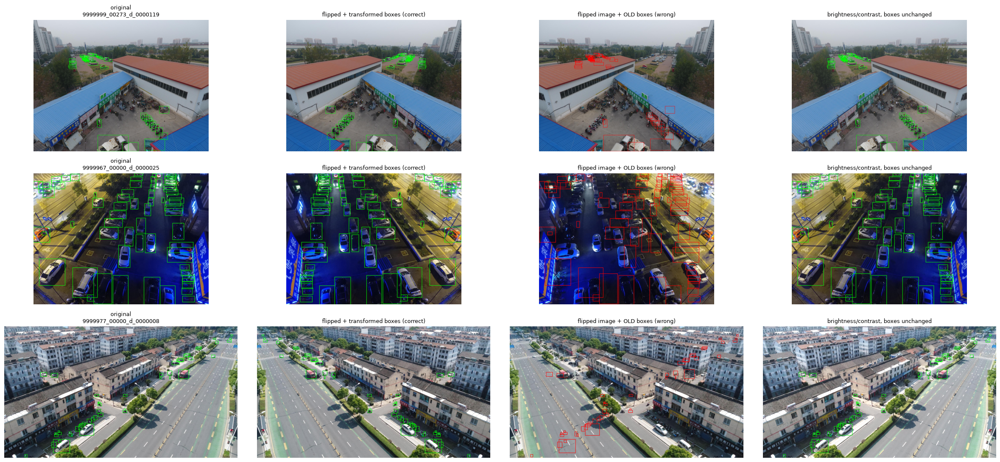

In [22]:
rng = np.random.default_rng(7)
cands = images_df[(images_df.split == "train") & images_df.n_objects.between(40, 120)].image_id.values
chosen = rng.choice(cands, 3, replace=False)

def draw(im, boxes, color):                              # colors are RGB here
    im = im.copy()
    for x1, y1, x2, y2 in boxes:
        cv2.rectangle(im, (int(x1), int(y1)), (int(x2), int(y2)), color, 2)
    return im

GREEN, RED = (0, 255, 0), (255, 0, 0)
fig, axes = plt.subplots(3, 4, figsize=(24, 11))
for row, iid in zip(axes, chosen):
    img, bboxes, labels = load_sample("train", iid)
    fl = flip_only(image=img, bboxes=bboxes, class_labels=labels)
    co = color_only(image=img, bboxes=bboxes, class_labels=labels)
    panels = [
        (draw(img, bboxes, GREEN),                       f"original\n{iid}"),
        (draw(fl["image"], fl["bboxes"], GREEN),         "flipped + transformed boxes (correct)"),
        (draw(fl["image"], bboxes, RED),                 "flipped image + OLD boxes (wrong)"),
        (draw(co["image"], co["bboxes"], GREEN),         "brightness/contrast, boxes unchanged"),
    ]
    for ax, (im, title) in zip(row, panels):
        ax.imshow(im); ax.set_title(title, fontsize=9); ax.axis("off")
plt.tight_layout()
plt.savefig(FIG / "augmentation_check.png", dpi=90)
plt.show()

image brightness per split


brightness: 100%|██████████████████████████| 8629/8629 [01:43<00:00, 83.54it/s]


        count   mean   std   min    5%    50%    95%    max
split                                                      
test   1610.0   84.0  36.6  13.7  27.1   82.9  141.1  219.8
train  6471.0   95.7  33.4   2.1  28.9  102.8  139.6  222.7
val     548.0  117.1  22.1  25.9  82.4  118.2  149.4  188.9
               count   mean
split id_9999              
test  False      252  113.0
      True      1358   78.7
train False     1332  115.7
      True      5139   90.5
val   False      548  117.1


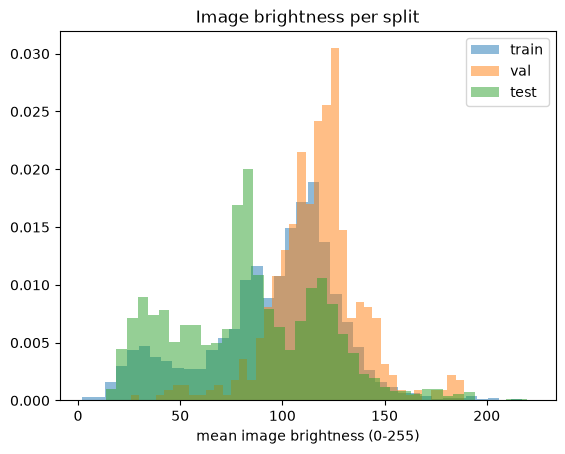

In [23]:
bright = []
for pth in tqdm(images_df["path"], desc="brightness"):
    g = cv2.imread(pth, cv2.IMREAD_REDUCED_GRAYSCALE_4)   # grayscale at 1/4 size = fast
    bright.append(float(g.mean()))
images_df["brightness"] = bright                           # 0 = black, 255 = white

print(images_df.groupby("split")["brightness"]
      .describe(percentiles=[0.05, 0.5, 0.95]).round(1))

images_df["id_9999"] = images_df.image_id.str.startswith("9999")
print(images_df.groupby(["split", "id_9999"])["brightness"].agg(["count", "mean"]).round(1))

for sp in SPLITS:
    plt.hist(images_df.loc[images_df.split == sp, "brightness"],
             bins=40, alpha=0.5, density=True, label=sp)
plt.xlabel("mean image brightness (0-255)"); plt.legend()
plt.title("Image brightness per split")
plt.savefig(FIG / "brightness_per_split.png", dpi=110); plt.show()

damage test for random crop and rotation

In [24]:
rng = np.random.default_rng(42)
tt = t_ok.merge(images_df[["split", "image_id", "W", "H"]], on=["split", "image_id"])
tt = tt[tt.split == "train"]
ids = rng.choice(tt.image_id.unique(), 200, replace=False)

crop_vis, crop_small = [], []          # visible fraction of every box after a 50% crop
rot_infl, rot_vis = [], []             # box area growth and share kept inside the frame

for iid in ids:
    b = tt[tt.image_id == iid]
    W, H = int(b.W.iloc[0]), int(b.H.iloc[0])
    x1, y1 = b.x.values.astype(float), b.y.values.astype(float)
    x2, y2 = x1 + b.w.values, y1 + b.h.values
    area = (x2 - x1) * (y2 - y1)

    # --- random crop: a random window with 50% of the width and 50% of the height ---
    cw, ch = W // 2, H // 2
    ox, oy = rng.integers(0, W - cw + 1), rng.integers(0, H - ch + 1)
    vw = np.clip(np.minimum(x2, ox + cw) - np.maximum(x1, ox), 0, None)
    vh = np.clip(np.minimum(y2, oy + ch) - np.maximum(y1, oy), 0, None)
    crop_vis.append(vw * vh / area)                       # 1 = fully inside, 0 = gone
    crop_small.append(area < 32 ** 2)

    # --- rotation by a random angle in [-15, 15] degrees around the image centre ---
    th = np.deg2rad(rng.uniform(-15, 15)); c, s = np.cos(th), np.sin(th)
    cx, cy = W / 2, H / 2
    xs = np.stack([x1, x2, x2, x1]); ys = np.stack([y1, y1, y2, y2])   # 4 corners per box
    rx = cx + (xs - cx) * c - (ys - cy) * s
    ry = cy + (xs - cx) * s + (ys - cy) * c
    nx1, nx2, ny1, ny2 = rx.min(0), rx.max(0), ry.min(0), ry.max(0)    # new axis-aligned box
    new_area = (nx2 - nx1) * (ny2 - ny1)
    rot_infl.append(new_area / area)                      # >1 = box now holds more background
    inside_w = np.clip(np.minimum(nx2, W) - np.maximum(nx1, 0), 0, None)
    inside_h = np.clip(np.minimum(ny2, H) - np.maximum(ny1, 0), 0, None)
    rot_vis.append(inside_w * inside_h / new_area)        # share of the new box inside the frame

crop_vis, crop_small = np.concatenate(crop_vis), np.concatenate(crop_small)
rot_infl, rot_vis = np.concatenate(rot_infl), np.concatenate(rot_vis)

def shares(v):
    return {"fully inside (>=99%)": (v >= 0.99).mean(),
            "partly cut (50-99%)": ((v >= 0.5) & (v < 0.99)).mean(),
            "lost (<50% visible)": (v < 0.5).mean()}

print("boxes tested:", len(crop_vis))
print("\nRandom crop (50% x 50% window), share of boxes, %:")
print(pd.DataFrame({"all boxes": shares(crop_vis),
                    "small boxes": shares(crop_vis[crop_small]),
                    "medium+large boxes": shares(crop_vis[~crop_small])}).mul(100).round(1))
print("\nRotation +-15 deg:")
print("mean box area growth: x", round(float(rot_infl.mean()), 2),
      "| median x", round(float(np.median(rot_infl)), 2))
print("boxes lost (<50% inside the frame), %:", round(float((rot_vis < 0.5).mean() * 100), 1))

boxes tested: 10711

Random crop (50% x 50% window), share of boxes, %:
                      all boxes  small boxes  medium+large boxes
fully inside (>=99%)       32.4         34.8                28.4
partly cut (50-99%)         3.3          1.6                 6.0
lost (<50% visible)        64.3         63.5                65.5

Rotation +-15 deg:
mean box area growth: x 1.27 | median x 1.26
boxes lost (<50% inside the frame), %: 1.9


## Domain shift between splits

**What this does:** compares train, val and test on properties that describe how the data was collected, to see whether the three splits come from the same distribution. Domain shift means P_train(X, Y) ≠ P_deployment(X, Y). The task gives no deployment data, so train is the reference and val and test are compared with it.

- **Resolution:** image sizes per split.
- **Lighting:** image brightness (measured earlier).
- **Object scale:** box size on the original image and after resizing to 640 (a proxy for shooting height and resolution).
- **Scene:** objects per image and class mix.
- One summary table collects all of these per split.

**Limits:** the files carry no camera, altitude, weather or season information, so those cannot be measured directly. A difference in a measured property shows a risk, not proof that a model will do worse.

image sizes per split:

In [25]:
sizes = images_df.assign(size=images_df.W.astype(str) + "x" + images_df.H.astype(str))
counts = sizes.groupby(["size", "split"]).size().unstack(fill_value=0)[list(SPLITS)]
share = (counts / counts.sum() * 100).round(1)          # % of the split's images

top = counts.sum(axis=1).sort_values(ascending=False).head(10).index
pd.set_option("display.width", 200)
print(pd.concat({"images": counts.loc[top], "share_%": share.loc[top]}, axis=1))
print("\nimages with other sizes:", counts.drop(top).sum().to_dict())

images_df["megapixels"] = images_df.W * images_df.H / 1e6
print("\nmegapixels per image:")
print(images_df.groupby("split")["megapixels"].describe(percentiles=[0.5]).round(2).reindex(list(SPLITS)))

          images           share_%            
split      train  val test   train   val  test
size                                          
1400x1050   2498    0  274    38.6   0.0  17.0
1400x788    1299    0  933    20.1   0.0  58.0
1360x765     743  408  167    11.5  74.5  10.4
2000x1500    772    0    0    11.9   0.0   0.0
1916x1078    537    0  151     8.3   0.0   9.4
960x540      250  121   49     3.9  22.1   3.0
1920x1080    339   19   36     5.2   3.5   2.2
1398x1048     30    0    0     0.5   0.0   0.0
1344x756       1    0    0     0.0   0.0   0.0
1389x1042      1    0    0     0.0   0.0   0.0

images with other sizes: {'train': 1, 'val': 0, 'test': 0}

megapixels per image:
        count  mean   std   min   50%   max
split                                      
train  6471.0  1.57  0.63  0.17  1.47  3.00
val     548.0  0.96  0.30  0.52  1.04  2.07
test   1610.0  1.25  0.35  0.52  1.10  2.07


summary table of everything per split:


In [26]:
# all target boxes with their image size (ignored regions and w/h <= 0 excluded)
tt = boxes_df[boxes_df.is_target & (boxes_df.w > 0) & (boxes_df.h > 0)].merge(
    images_df[["split", "image_id", "W", "H"]], on=["split", "image_id"])
tt["area"] = tt.w * tt.h
scale640 = np.minimum(640 / tt.W, 640 / tt.H)                # whole image fitted into 640x640
tt["small"] = tt.area < 32 ** 2
tt["small640"] = tt.area * scale640 ** 2 < 32 ** 2

g_img, g_box = images_df.groupby("split"), tt.groupby("split")

# class mix: share of each class inside its split, and the distance of val/test from train
cls = tt.groupby(["split", "category"]).size().unstack(fill_value=0)
cls_share = cls.div(cls.sum(axis=1), axis=0)
# total variation distance = half of the sum of absolute share differences:
# the % of targets whose class would have to change to match the train mix
tv = {s: 0.5 * (cls_share.loc[s] - cls_share.loc["train"]).abs().sum() * 100 for s in SPLITS}

summary = pd.DataFrame({
    "images":                          g_img.size(),
    "median image width, px":          g_img["W"].median(),
    "mean megapixels":                 g_img["megapixels"].mean(),
    "mean brightness (0-255)":         g_img["brightness"].mean(),
    "brightness 5th percentile":       g_img["brightness"].quantile(0.05),
    "brightness std":                  g_img["brightness"].std(),
    "median targets per image":        g_img["n_objects"].median(),
    "P95 targets per image":           g_img["n_objects"].quantile(0.95),
    "median box side, px":             g_box["area"].median() ** 0.5,
    "small boxes, % (original)":       g_box["small"].mean() * 100,
    "small boxes, % (at 640)":         g_box["small640"].mean() * 100,
    "car share, %":                    cls_share[4] * 100,
    "pedestrian share, %":             cls_share[1] * 100,
    "people share, %":                 cls_share[2] * 100,
    "motor share, %":                  cls_share[10] * 100,
    "bus share, %":                    cls_share[9] * 100,
    "class mix distance from train, %": pd.Series(tv),
}).reindex(list(SPLITS)).T
print(summary.round(1).to_string())

                                   train     val    test
images                            6471.0   548.0  1610.0
median image width, px            1400.0  1360.0  1400.0
mean megapixels                      1.6     1.0     1.3
mean brightness (0-255)             95.7   117.1    84.0
brightness 5th percentile           28.9    82.4    27.1
brightness std                      33.4    22.1    36.6
median targets per image            42.0    65.0    36.0
P95 targets per image              132.0   157.6   123.0
median box side, px                 26.1    22.8    21.9
small boxes, % (original)           60.5    68.6    67.7
small boxes, % (at 640)             90.6    92.4    93.2
car share, %                        42.2    36.3    37.4
pedestrian share, %                 23.1    22.8    28.0
people share, %                      7.9    13.2     8.5
motor share, %                       8.6    12.6     7.8
bus share, %                         1.7     0.6     3.9
class mix distance from train, 

In [27]:
print(images_df.sort_values("megapixels").head(3)[["split", "image_id", "W", "H", "megapixels"]])

      split                 image_id    W    H  megapixels
6358  train  9999999_00650_d_0000295  480  360      0.1728
6551    val  0000153_01801_d_0000001  960  540      0.5184
6550    val  0000153_01601_d_0000001  960  540      0.5184


targets: 27 | median box side, px: 10.198039027185569


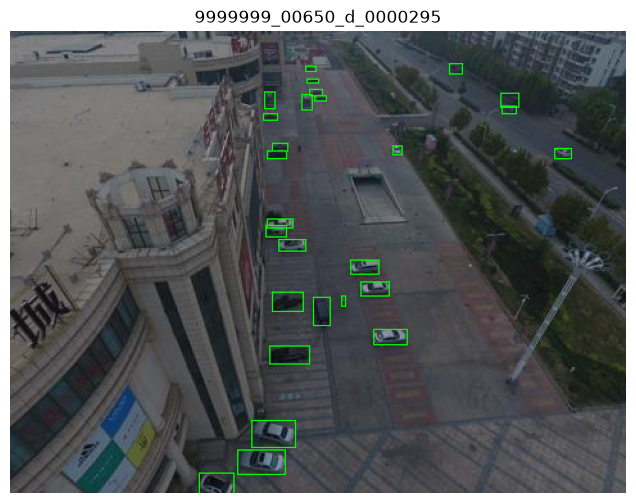

In [28]:
iid = "9999999_00650_d_0000295"
img = cv2.cvtColor(cv2.imread(str(img_path("train", iid))), cv2.COLOR_BGR2RGB)
b = boxes_df[(boxes_df.image_id == iid) & boxes_df.is_target]
for r in b.itertuples():
    cv2.rectangle(img, (r.x, r.y), (r.x + r.w, r.y + r.h), (0, 255, 0), 1)
print("targets:", len(b), "| median box side, px:", float(np.sqrt(b.w * b.h).median()) if len(b) else None)
plt.figure(figsize=(8, 6)); plt.imshow(img); plt.axis("off"); plt.title(iid); plt.show()